# Residual CNN under 5M parameters on CIFAR-10: training notebook (design exploration)

Author: Zhongbo Liu. NYU Deep Learning F26, Project 1.

This Google Colab notebook trained every run in the **design-exploration and ablation** study of the report
(architectures A/B/C, augmentation, training length, CutMix, SAM, batch size, SWA, multi-view TTA).
The team's **final Kaggle submission** is the WRN-28-56 model in the main repository (`src/`, `Colab_Training.ipynb`);
the best model from this notebook (`arch_C_300ep`, 4,781,374 parameters) scored 0.889 / 0.891 on the public leaderboard.

**How it is used.** Cells 1–8 load data and define the model, augmentations and helpers. The `CFG` dictionary in
cell 4 describes one run; cell 9 trains it, saves `log.csv` / `model.pt` in `runs/<run_name>/`, and appends a
row to `experiments.csv`. Every run in the report was produced by editing `CFG` and re-running cells 4–9, so the
outputs visible below belong to the **last run executed** (`arch_C_300ep_cutmix_bs128`). The records of all other
runs are in `experiments.csv` and `logs/*/log.csv`, analysed in `results_analysis.ipynb`.

**Rules respected.** Training from scratch (no pretrained weights, no external data). Validation uses a stratified
45,000 / 5,000 split of the provided training images (seed 42). Test images are used only to write the submission file.

| `CFG` of the runs in the report | channels | blocks | epochs | other changes |
|---|---|---|---|---|
| v1_baseline | (64,128,256,512) | (2,1,1,1) | 30 | crop + flip only |
| v2_blur_noise | same | same | 30 | + random blur/sharpen, Gaussian noise |
| v3_80epochs | same | same | 80 | |
| v4_ls_cutout | same | same | 80 | + label smoothing 0.1, Cutout 16 |
| v5a / v5b (= architecture A) | same | same | 80 / 150 | + TrivialAugment |
| arch_B_deep_narrow | (42,84,168,336) | (2,2,2,2) | 80 | as v5a |
| arch_C_wide_3stage / _150ep / _300ep | (84,168,336) | (2,2,2) | 80 / 150 / 300 | as v5a |
| arch_C_300ep_cutmix | (84,168,336) | (2,2,2) | 300 | + CutMix p=0.5 |
| arch_C_300ep_sam | same | same | 300 | + SAM rho=0.05 |
| arch_C_300ep_cutmix_bs128 | same | same | 300 | CutMix, batch 128 |
| final_full_* | | | | `full_train=True` (all 50,000 images) |


## 1. Environment check

In [1]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
print("GPU name:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
GPU available: True
GPU name: NVIDIA L4


## 2. Mount Google Drive and unpack `data.zip`

In [3]:
import os
import zipfile
from google.colab import drive

drive.mount('/content/drive')

DRIVE_DIR = '/content/drive/MyDrive/DL_Project1'
ZIP_PATH  = os.path.join(DRIVE_DIR, 'data.zip')
DATA_DIR  = '/content/data'

if not os.path.exists(os.path.join(DATA_DIR, 'train_labels.csv')):
    print("Unzipping...")
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(DATA_DIR)
    print("Done.")
else:
    print("Data already unzipped.")

print("Files:", os.listdir(DATA_DIR))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Unzipping...
Done.
Files: ['test_images', 'train_labels.csv', 'sample_submission.csv', 'test.csv', 'train_images']


## 3. Load images into memory

In [4]:
import numpy as np
import pandas as pd
from PIL import Image

train_df  = pd.read_csv(os.path.join(DATA_DIR, 'train_labels.csv'))
test_df   = pd.read_csv(os.path.join(DATA_DIR, 'test.csv'))
sample_df = pd.read_csv(os.path.join(DATA_DIR, 'sample_submission.csv'))

def load_images(folder, filenames):
    return np.stack([np.array(Image.open(os.path.join(folder, f)).convert('RGB'))
                     for f in filenames])

X_all  = load_images(os.path.join(DATA_DIR, 'train_images'), train_df['filename'])
y_all  = train_df['label'].values
X_test = load_images(os.path.join(DATA_DIR, 'test_images'), test_df['filename'])

print("Train images:", X_all.shape, X_all.dtype)
print("Train labels:", y_all.shape)
print("Test images: ", X_test.shape)
print("Images per class:", np.bincount(y_all))
assert (test_df['id'].values == sample_df['id'].values).all(), "test.csv and sample_submission.csv order differ!"
print("test.csv order matches sample_submission.csv")

Train images: (50000, 32, 32, 3) uint8
Train labels: (50000,)
Test images:  (2000, 32, 32, 3)
Images per class: [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]
test.csv order matches sample_submission.csv


## 4. Stratified train / validation split (500 images per class, seed 42)

In [5]:
import random

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

VAL_PER_CLASS = 500
rng = np.random.RandomState(SEED)
val_idx = []
for c in range(10):
    idx_c = np.where(y_all == c)[0]
    rng.shuffle(idx_c)
    val_idx.extend(idx_c[:VAL_PER_CLASS])
val_idx   = np.sort(np.array(val_idx))
train_idx = np.setdiff1d(np.arange(len(y_all)), val_idx)

X_train, y_train = X_all[train_idx], y_all[train_idx]
X_val,   y_val   = X_all[val_idx],   y_all[val_idx]

print("Train:", X_train.shape, " per class:", np.bincount(y_train))
print("Val:  ", X_val.shape,   " per class:", np.bincount(y_val))
assert len(np.intersect1d(train_idx, val_idx)) == 0, "Overlap between train and val!"
print("No overlap between train and val")

Train: (45000, 32, 32, 3)  per class: [4500 4500 4500 4500 4500 4500 4500 4500 4500 4500]
Val:   (5000, 32, 32, 3)  per class: [500 500 500 500 500 500 500 500 500 500]
No overlap between train and val


## 5. Run configuration (`CFG`)
Edit this cell to define a run. Shown: the last run executed.

In [7]:
CFG = dict(
    run_name        = 'arch_C_300ep_cutmix_bs128',
    full_train      = False,
    channels        = (84, 168, 336),
    blocks          = (2, 2, 2),
    epochs          = 300,
    batch_size      = 128,
    lr              = 0.1,
    momentum        = 0.9,
    weight_decay    = 5e-4,
    label_smoothing = 0.1,
    sam_rho         = 0.0,
    aug_trivial     = True,
    ta_chunk        = 16,
    aug_crop        = True,
    aug_flip        = True,
    aug_cutout      = 16,
    aug_sharpness   = 0.0,
    aug_noise       = 0.0,
    cutmix_prob     = 0.5,
    cutmix_alpha    = 1.0,
    tta_flip        = True,
)
RUN_DIR = os.path.join(DRIVE_DIR, 'runs', CFG['run_name'])
os.makedirs(RUN_DIR, exist_ok=True)
print("Results will be saved to:", RUN_DIR, "| batch size:", CFG['batch_size'], "| epochs:", CFG['epochs'])

Results will be saved to: /content/drive/MyDrive/DL_Project1/runs/arch_C_300ep_cutmix_bs128 | batch size: 128 | epochs: 300


## 6. Model: ResNet with BasicBlocks, parameter check (< 5M)

In [8]:
import torch.nn as nn
import torch.nn.functional as F

device = 'cuda'

class BasicBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1   = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2   = nn.BatchNorm2d(out_ch)
        if stride != 1 or in_ch != out_ch:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_ch))
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return F.relu(out + self.shortcut(x))      # y = F(x) + S(x)


class ResNet(nn.Module):
    def __init__(self, channels, blocks, num_classes=10):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, channels[0], kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(channels[0]),
            nn.ReLU(inplace=True))
        layers, in_ch = [], channels[0]
        for i, (ch, n) in enumerate(zip(channels, blocks)):
            for j in range(n):
                stride = 2 if (i > 0 and j == 0) else 1
                layers.append(BasicBlock(in_ch, ch, stride))
                in_ch = ch
        self.layers = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc   = nn.Linear(in_ch, num_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.layers(x)
        x = self.pool(x).flatten(1)
        return self.fc(x)


model = ResNet(CFG['channels'], CFG['blocks']).to(device)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters: {n_params:,}")
assert n_params <= 5_000_000, "Model exceeds the 5M parameter limit!"
print("Under the 5M limit")

dummy = torch.randn(2, 3, 32, 32, device=device)
print("Output shape:", model(dummy).shape)

Trainable parameters: 4,781,374
Under the 5M limit
Output shape: torch.Size([2, 10])


## 7. Data pipeline on the GPU: normalisation, TrivialAugment, crop / flip / Cutout, evaluation with flip TTA, CutMix

torchvision version: 0.26.0+cu130
On GPU: torch.Size([45000, 3, 32, 32]) torch.uint8 | torch.Size([5000, 3, 32, 32]) torch.Size([2000, 3, 32, 32])


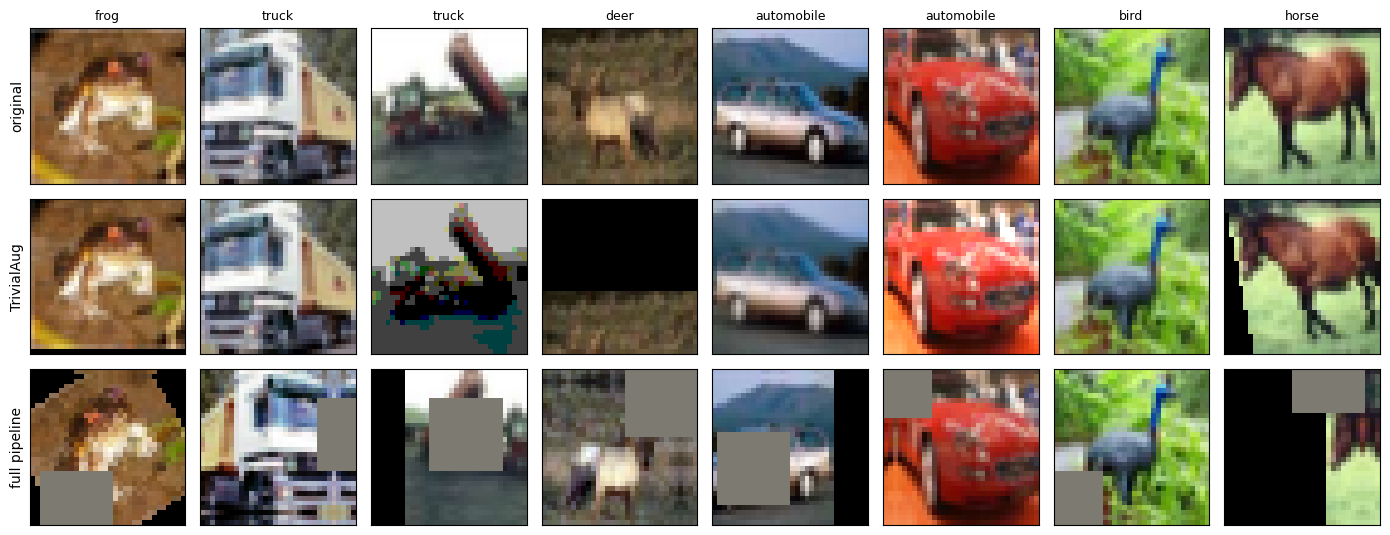

cutmix function ready: True


In [9]:
import math
import matplotlib.pyplot as plt
import torchvision
from torchvision.transforms import v2 as T2

print("torchvision version:", torchvision.__version__)

# ---------- 1. Normalization ----------
MEAN = torch.tensor([0.4914, 0.4822, 0.4465], device=device).view(1, 3, 1, 1)
STD  = torch.tensor([0.2470, 0.2435, 0.2616], device=device).view(1, 3, 1, 1)

def to_gpu_u8(X):
    # numpy (N, 32, 32, 3) uint8 -> torch (N, 3, 32, 32) uint8 on GPU
    return torch.from_numpy(X).to(device).permute(0, 3, 1, 2).contiguous()

def normalize_u8(x_u8):
    # uint8 0-255 -> float, normalized
    return (x_u8.float() / 255.0 - MEAN) / STD

def to_gpu_tensor(X):
    return normalize_u8(to_gpu_u8(X))

# ---------- 2. Data on GPU ----------
if CFG.get('full_train', False):
    Xtr_u8 = to_gpu_u8(X_all)                # ALL 50,000 images (validation included)
    ytr    = torch.from_numpy(y_all).to(device)
    print("FULL TRAINING: all 50,000 images are used; validation accuracy is NOT meaningful")
else:
    Xtr_u8 = to_gpu_u8(X_train)              # 45,000 training images
    ytr    = torch.from_numpy(y_train).to(device)
Xtr    = normalize_u8(Xtr_u8)                # normalized copy, used for previews
Xva, yva = to_gpu_tensor(X_val), torch.from_numpy(y_val).to(device)
Xte      = to_gpu_tensor(X_test)
print("On GPU:", Xtr_u8.shape, Xtr_u8.dtype, "|", Xva.shape, Xte.shape)

# ---------- 3. TrivialAugmentWide (raw uint8 pixels, on GPU) ----------
TRIVIAL_AUG = T2.TrivialAugmentWide()

def trivial_augment(x_u8, chunk=16):
    # one random op per chunk of images; input/output uint8 on GPU
    return torch.cat([TRIVIAL_AUG(c) for c in x_u8.split(chunk)])

# ---------- 4. Other augmentations (normalized float tensors) ----------
def augment(x, cfg):
    n, dev = x.size(0), x.device

    if cfg['aug_crop']:                                   # (a) random crop
        p = 4
        xp = F.pad(x, (p, p, p, p), mode='reflect')
        i = torch.randint(0, 2 * p + 1, (n,), device=dev)
        j = torch.randint(0, 2 * p + 1, (n,), device=dev)
        r = torch.arange(32, device=dev)
        rows = (i[:, None] + r)[:, None, :, None]
        cols = (j[:, None] + r)[:, None, None, :]
        x = xp[torch.arange(n, device=dev)[:, None, None, None],
               torch.arange(3, device=dev)[None, :, None, None], rows, cols]

    if cfg['aug_flip']:                                   # (b) horizontal flip
        flip = torch.rand(n, device=dev) < 0.5
        x = torch.where(flip[:, None, None, None], x.flip(3), x)

    p_sharp = cfg.get('aug_sharpness', 0)                 # (c) blur / sharpen
    if p_sharp > 0:
        blurred = F.avg_pool2d(x, 3, stride=1, padding=1, count_include_pad=False)
        a = torch.empty(n, device=dev).uniform_(-1.0, 1.0)
        a = torch.where(torch.rand(n, device=dev) < p_sharp, a, torch.zeros_like(a))
        x = x + a[:, None, None, None] * (blurred - x)

    noise_max = cfg.get('aug_noise', 0)                   # (d) noise
    if noise_max > 0:
        level = torch.rand(n, device=dev) * noise_max
        x = x + torch.randn_like(x) * level[:, None, None, None] / STD

    s = cfg['aug_cutout']                                 # (e) cutout
    if s > 0:
        cy = torch.randint(0, 32, (n,), device=dev)
        cx = torch.randint(0, 32, (n,), device=dev)
        r = torch.arange(32, device=dev)
        mask_y = (r[None, :] - cy[:, None]).abs() < s / 2
        mask_x = (r[None, :] - cx[:, None]).abs() < s / 2
        mask = mask_y[:, :, None] & mask_x[:, None, :]
        x = x * (~mask)[:, None].float()

    return x

# ---------- 5. Full training pipeline for one batch ----------
#   raw uint8 -> [TrivialAugment] -> normalize -> crop -> flip -> cutout
def prepare_batch(idx, cfg):
    x_u8 = Xtr_u8[idx]
    if cfg.get('aug_trivial', False):
        x_u8 = trivial_augment(x_u8, cfg.get('ta_chunk', 16))
    return augment(normalize_u8(x_u8), cfg)

# ---------- 6. Preview ----------
def to_image(x):
    return (x * STD[0] + MEAN[0]).clamp(0, 1).permute(1, 2, 0).cpu().numpy()

CLASSES = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
idx8 = torch.arange(8, device=device)
orig = Xtr_u8[idx8]
ta_only = trivial_augment(orig, chunk=1) if CFG.get('aug_trivial', False) else orig
full = prepare_batch(idx8, {**CFG, 'ta_chunk': 1})

fig, axes = plt.subplots(3, 8, figsize=(14, 5.5))
for k in range(8):
    axes[0, k].imshow(orig[k].permute(1, 2, 0).cpu().numpy()); axes[0, k].set_title(CLASSES[ytr[k]], fontsize=9)
    axes[1, k].imshow(ta_only[k].permute(1, 2, 0).cpu().numpy())
    axes[2, k].imshow(to_image(full[k]))
for a in axes.flat:
    a.set_xticks([]); a.set_yticks([])
axes[0, 0].set_ylabel('original'); axes[1, 0].set_ylabel('TrivialAug'); axes[2, 0].set_ylabel('full pipeline')
plt.tight_layout(); plt.show()

# ---------- 7. Evaluation helper ----------
def evaluate(model, X, y=None, tta=False, bs=1000):
    model.eval()
    probs = []
    with torch.no_grad(), torch.autocast('cuda', dtype=torch.float16):
        for k in range(0, len(X), bs):
            xb = X[k:k + bs]
            p = model(xb).float().softmax(1)
            if tta:
                p = (p + model(xb.flip(3)).float().softmax(1)) / 2
            probs.append(p)
    probs = torch.cat(probs)
    if y is None:
        return probs
    loss = F.nll_loss(probs.clamp_min(1e-8).log(), y).item()
    acc = (probs.argmax(1) == y).float().mean().item()
    return probs, loss, acc

# ---------- 8. CutMix: paste a random box from another image, mix labels by area ----------
def cutmix(x, y, alpha=1.0):
    n = x.size(0)
    lam = torch.distributions.Beta(alpha, alpha).sample().item()
    perm = torch.randperm(n, device=x.device)
    cut = math.sqrt(1 - lam)
    ch, cw = int(32 * cut), int(32 * cut)
    cy = torch.randint(0, 32, (1,)).item()
    cx = torch.randint(0, 32, (1,)).item()
    y1, y2 = max(cy - ch // 2, 0), min(cy + ch // 2, 32)
    x1, x2 = max(cx - cw // 2, 0), min(cx + cw // 2, 32)
    x[:, :, y1:y2, x1:x2] = x[perm][:, :, y1:y2, x1:x2]
    lam = 1 - (y2 - y1) * (x2 - x1) / (32 * 32)      # actual area kept
    return x, y[perm], lam

print("cutmix function ready:", callable(cutmix))

## 8. Pre-flight checks (augmentation output, one training step, timing)

In [10]:
import time, math

BS = CFG['batch_size']
idx = torch.randperm(len(ytr), device=device)[:BS]

# 1. TrivialAugment output
if CFG.get('aug_trivial', False):
    ta = trivial_augment(Xtr_u8[idx], CFG.get('ta_chunk', 16))
    print("TrivialAug output:", tuple(ta.shape), ta.dtype, ta.device,
          "| range", ta.min().item(), "-", ta.max().item())
    assert ta.shape == Xtr_u8[idx].shape, "shape changed"
    assert ta.dtype == torch.uint8 and ta.device.type == 'cuda', "dtype/device changed"

# 2. Full pipeline batch
xb, yb = prepare_batch(idx, CFG), ytr[idx]
print(f"Batch: {tuple(xb.shape)} {xb.dtype} | min {xb.min():.2f} max {xb.max():.2f} "
      f"mean {xb.mean():.2f} std {xb.std():.2f}")
assert xb.shape == (BS, 3, 32, 32) and xb.dtype == torch.float32
assert torch.isfinite(xb).all(), "NaN/Inf in batch"
assert xb.min() > -3 and xb.max() < 3, "values outside the normalized range"
assert yb.min() >= 0 and yb.max() <= 9
print("Labels per class in this batch:", torch.bincount(yb, minlength=10).tolist())

# 3. One training step on a throwaway model
tmp = ResNet(CFG['channels'], CFG['blocks']).to(device)
assert sum(p.numel() for p in tmp.parameters() if p.requires_grad) <= 5_000_000
opt_tmp = torch.optim.SGD(tmp.parameters(), lr=0.01, momentum=0.9)
scaler_tmp = torch.amp.GradScaler('cuda')
crit = nn.CrossEntropyLoss(label_smoothing=CFG['label_smoothing'])
tmp.train()

def train_step():
    x = prepare_batch(idx, CFG)
    with torch.autocast('cuda', dtype=torch.float16):
        l = crit(tmp(x), yb)
    opt_tmp.zero_grad(set_to_none=True)
    scaler_tmp.scale(l).backward(); scaler_tmp.step(opt_tmp); scaler_tmp.update()
    return l

w0 = tmp.fc.weight.detach().clone()
for attempt in range(3):
    loss = train_step()
    if not torch.equal(w0, tmp.fc.weight.detach()):
        break
print(f"One-step loss: {loss.item():.3f} (expect ~2.3)")
assert torch.isfinite(loss), "loss is NaN/Inf"
assert not torch.equal(w0, tmp.fc.weight.detach()), "weights did not update"

# 4. Speed test
def timeit(fn, n=20):
    fn(); torch.cuda.synchronize(); t = time.time()
    for _ in range(n):
        fn()
    torch.cuda.synchronize()
    return (time.time() - t) / n

t_base = timeit(lambda: augment(normalize_u8(Xtr_u8[idx]), CFG))
print(f"\nAugmentation per batch WITHOUT TrivialAug: {t_base*1000:.1f} ms")
for ch in [1, 4, 16]:
    t_ta = timeit(lambda ch=ch: trivial_augment(Xtr_u8[idx], ch))
    print(f"TrivialAug per batch, chunk={ch:<2d}: {t_ta*1000:.1f} ms")

t_step = timeit(train_step)
steps = math.ceil(len(ytr) / BS)
est_epoch = t_step * steps + 1.0
print(f"\nFull training step (chunk={CFG.get('ta_chunk')}): {t_step*1000:.1f} ms")
print(f"Estimated: {est_epoch:.0f} s / epoch  ->  {est_epoch*CFG['epochs']/60:.0f} min for {CFG['epochs']} epochs")
print("Reference: v4 took ~13 s / epoch, 17 min for 80 epochs")

del tmp, opt_tmp, scaler_tmp
torch.cuda.empty_cache()
print("\nALL PRE-FLIGHT CHECKS PASSED")

TrivialAug output: (128, 3, 32, 32) torch.uint8 cuda:0 | range 0 - 255
Batch: (128, 3, 32, 32) torch.float32 | min -1.99 max 2.13 mean -0.06 std 0.89
Labels per class in this batch: [16, 18, 10, 6, 7, 16, 13, 9, 20, 13]
One-step loss: 2.417 (expect ~2.3)

Augmentation per batch WITHOUT TrivialAug: 0.7 ms
TrivialAug per batch, chunk=1 : 44.2 ms
TrivialAug per batch, chunk=4 : 11.3 ms
TrivialAug per batch, chunk=16: 2.9 ms

Full training step (chunk=16): 33.8 ms
Estimated: 13 s / epoch  ->  64 min for 300 epochs
Reference: v4 took ~13 s / epoch, 17 min for 80 epochs

ALL PRE-FLIGHT CHECKS PASSED


In [11]:
print("Training images on GPU:", Xtr_u8.shape[0], "| full_train =", CFG['full_train'])

Training images on GPU: 45000 | full_train = False


## 9. Training loop
SGD (Nesterov, momentum 0.9, weight decay 5e-4 not applied to BN / bias), OneCycle LR (max 0.1), mixed precision,
label smoothing, optional CutMix / SAM. Saves checkpoints, `log.csv`, and a row in `experiments.csv`.
The output below is the full 300-epoch log and the curves of `arch_C_300ep_cutmix_bs128`.

Run: arch_C_300ep_cutmix_bs128 | trainable parameters: 4,781,374
Optimizer: SGD
Epoch   1/300 | train loss 2.052 acc 28.37% | val loss 1.356 acc 51.88% | 13s
Epoch   2/300 | train loss 1.906 acc 36.54% | val loss 1.237 acc 56.64% | 13s
Epoch   3/300 | train loss 1.790 acc 43.10% | val loss 1.087 acc 62.84% | 13s
Epoch   4/300 | train loss 1.759 acc 44.73% | val loss 1.033 acc 64.04% | 13s
Epoch   5/300 | train loss 1.703 acc 48.05% | val loss 0.934 acc 68.42% | 13s
Epoch   6/300 | train loss 1.686 acc 49.00% | val loss 0.820 acc 71.34% | 13s
Epoch   7/300 | train loss 1.681 acc 49.10% | val loss 0.756 acc 74.92% | 13s
Epoch   8/300 | train loss 1.624 acc 51.50% | val loss 0.792 acc 74.40% | 13s
Epoch   9/300 | train loss 1.618 acc 52.66% | val loss 0.733 acc 75.74% | 13s
Epoch  10/300 | train loss 1.589 acc 53.88% | val loss 0.726 acc 76.86% | 13s
Epoch  11/300 | train loss 1.568 acc 55.10% | val loss 0.728 acc 77.76% | 13s
Epoch  12/300 | train loss 1.576 acc 55.03% | val loss 0.670 a

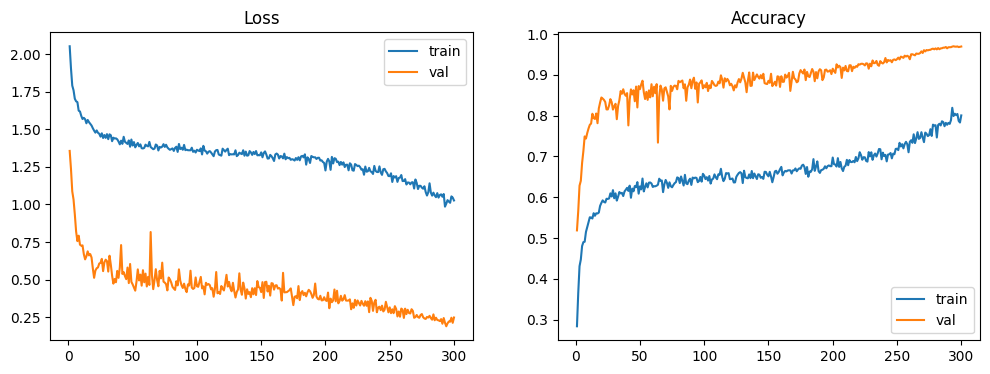

In [12]:
import time, math, json, datetime

# ---------- Fresh model + parameter check ----------
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
model = ResNet(CFG['channels'], CFG['blocks']).to(device)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
assert n_params <= 5_000_000, f"Model has {n_params:,} parameters (> 5M)!"
print(f"Run: {CFG['run_name']} | trainable parameters: {n_params:,}")

# ---------- Optimizer / schedule / loss ----------
decay    = [p for p in model.parameters() if p.ndim > 1]
no_decay = [p for p in model.parameters() if p.ndim <= 1]
optimizer = torch.optim.SGD(
    [{'params': decay, 'weight_decay': CFG['weight_decay']},
     {'params': no_decay, 'weight_decay': 0.0}],
    lr=CFG['lr'], momentum=CFG['momentum'], nesterov=True)

E, BS = CFG['epochs'], CFG['batch_size']
steps_per_epoch = math.ceil(len(ytr) / BS)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=CFG['lr'], epochs=E, steps_per_epoch=steps_per_epoch, pct_start=0.25)
criterion = nn.CrossEntropyLoss(label_smoothing=CFG['label_smoothing'])

# SAM uses bfloat16 (no GradScaler needed); normal training uses float16 + GradScaler
use_sam   = CFG.get('sam_rho', 0) > 0
amp_dtype = torch.bfloat16 if use_sam else torch.float16
if use_sam:
    assert torch.cuda.is_bf16_supported(), "SAM run needs bfloat16: switch to L4 or A100 (not T4)"
scaler = torch.amp.GradScaler('cuda', enabled=not use_sam)
params = list(model.parameters())
print("Optimizer:", f"SAM (rho={CFG['sam_rho']}) + SGD" if use_sam else "SGD")

def forward_loss(xb, yb, mix):
    with torch.autocast('cuda', dtype=amp_dtype):
        out = model(xb)
        if mix is None:
            loss = criterion(out, yb)
        else:
            yb_b, lam = mix
            loss = lam * criterion(out, yb) + (1 - lam) * criterion(out, yb_b)
    return out, loss

# ---------- Resume (only with the SAME CFG) ----------
ckpt_path = os.path.join(RUN_DIR, 'checkpoint.pt')
history, start_epoch, best_acc, best_epoch = [], 0, -1.0, 0
if os.path.exists(ckpt_path):
    ck = torch.load(ckpt_path, map_location=device)
    if 'cfg' in ck and ck['cfg'] != CFG:
        raise RuntimeError("This run folder was trained with a DIFFERENT CFG. "
                           "Change run_name in cell 5 to start a new experiment.")
    model.load_state_dict(ck['model']); optimizer.load_state_dict(ck['optimizer'])
    scheduler.load_state_dict(ck['scheduler']); scaler.load_state_dict(ck['scaler'])
    history, start_epoch = ck['history'], ck['epoch']
    best_acc, best_epoch = ck.get('best_acc', -1.0), ck.get('best_epoch', 0)
    if 'rng_cpu' in ck:
        torch.set_rng_state(ck['rng_cpu'].cpu())
        torch.cuda.set_rng_state(ck['rng_cuda'].cpu())
    print(f"Resuming from epoch {start_epoch}")

# ---------- Training loop ----------
for epoch in range(start_epoch, E):
    model.train()
    t0 = time.time()
    perm = torch.randperm(len(ytr), device=device)
    loss_sum = torch.zeros((), device=device)
    correct  = torch.zeros((), device=device)
    skipped  = 0

    for k in range(steps_per_epoch):
        idx = perm[k * BS:(k + 1) * BS]
        xb, yb = prepare_batch(idx, CFG), ytr[idx]

        mix = None
        if CFG.get('cutmix_prob', 0) > 0 and torch.rand(1).item() < CFG['cutmix_prob']:
            xb, yb_b, lam = cutmix(xb, yb, CFG.get('cutmix_alpha', 1.0))
            mix = (yb_b, lam)

        if use_sam:
            # 1) gradient at the current weights
            optimizer.zero_grad(set_to_none=True)
            out, loss = forward_loss(xb, yb, mix)
            loss.backward()
            # 2) step to the "worst" nearby point
            with torch.no_grad():
                gnorm = torch.norm(torch.stack([p.grad.norm(2) for p in params if p.grad is not None]), 2)
                scale = CFG['sam_rho'] / (gnorm + 1e-12)
                eps = []
                for p in params:
                    if p.grad is None:
                        eps.append(None); continue
                    e = p.grad * scale
                    p.add_(e); eps.append(e)
            # 3) gradient at that nearby point
            optimizer.zero_grad(set_to_none=True)
            _, loss2 = forward_loss(xb, yb, mix)
            loss2.backward()
            # 4) go back to the original weights and update with the new gradient
            with torch.no_grad():
                for p, e in zip(params, eps):
                    if e is not None:
                        p.sub_(e)
            optimizer.step()
            scheduler.step()
        else:
            out, loss = forward_loss(xb, yb, mix)
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scale_before = scaler.get_scale()
            scaler.step(optimizer); scaler.update()
            if scaler.get_scale() >= scale_before:
                scheduler.step()
            else:
                skipped += 1

        loss_sum += loss.detach() * len(yb)
        correct  += (out.argmax(1) == yb).sum()

    train_loss, train_acc = loss_sum.item() / len(ytr), correct.item() / len(ytr)
    _, val_loss, val_acc = evaluate(model, Xva, yva)
    sec = time.time() - t0
    history.append(dict(epoch=epoch + 1, lr=optimizer.param_groups[0]['lr'],
                        train_loss=train_loss, train_acc=train_acc,
                        val_loss=val_loss, val_acc=val_acc, seconds=sec, skipped_steps=skipped))
    print(f"Epoch {epoch+1:3d}/{E} | train loss {train_loss:.3f} acc {train_acc:.2%} "
          f"| val loss {val_loss:.3f} acc {val_acc:.2%} | {sec:.0f}s"
          + (f" | AMP skipped {skipped}" if skipped else ""))

    if val_acc > best_acc:
        best_acc, best_epoch = val_acc, epoch + 1
        torch.save(model.state_dict(), os.path.join(RUN_DIR, 'best_model.pt'))

    pd.DataFrame(history).to_csv(os.path.join(RUN_DIR, 'log.csv'), index=False)
    torch.save({'model': model.state_dict(), 'optimizer': optimizer.state_dict(),
                'scheduler': scheduler.state_dict(), 'scaler': scaler.state_dict(),
                'history': history, 'epoch': epoch + 1, 'cfg': CFG,
                'best_acc': best_acc, 'best_epoch': best_epoch,
                'rng_cpu': torch.get_rng_state(), 'rng_cuda': torch.cuda.get_rng_state()},
               ckpt_path)

# ---------- Final results (model.pt = LAST epoch) ----------
torch.save(model.state_dict(), os.path.join(RUN_DIR, 'model.pt'))
pd.DataFrame(history).to_csv(os.path.join(RUN_DIR, 'log.csv'), index=False)
_, _, val_acc     = evaluate(model, Xva, yva, tta=False)
_, _, val_acc_tta = evaluate(model, Xva, yva, tta=True)
minutes = sum(h['seconds'] for h in history) / 60
print(f"\nFinal val acc: {val_acc:.2%} | with flip TTA: {val_acc_tta:.2%} | total {minutes:.1f} min")
if best_epoch:
    print(f"Best val acc during training: {best_acc:.2%} at epoch {best_epoch}")

# ---------- Experiments table ----------
exp_path = os.path.join(DRIVE_DIR, 'experiments.csv')
exp = pd.read_csv(exp_path) if os.path.exists(exp_path) else pd.DataFrame()
row = dict(run_name=CFG['run_name'], date=datetime.datetime.now().strftime('%Y-%m-%d %H:%M'),
           params=n_params, epochs=E, val_acc=round(val_acc, 4), val_acc_tta=round(val_acc_tta, 4),
           best_val_acc=round(best_acc, 4) if best_epoch else None, best_epoch=best_epoch or None,
           minutes=round(minutes, 1), kaggle_public='', notes='', config=json.dumps(CFG))
if len(exp) and (exp['run_name'] == CFG['run_name']).any():
    old = exp[exp['run_name'] == CFG['run_name']].iloc[0]
    for col in ['kaggle_public', 'notes', 'robust_acc']:
        if col in old and pd.notna(old[col]):
            row[col] = old[col]
    exp = exp[exp['run_name'] != CFG['run_name']]
exp = pd.concat([exp, pd.DataFrame([row])], ignore_index=True)
exp.to_csv(exp_path, index=False)
print("Saved to experiments.csv")

# ---------- Training curves ----------
h = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h.epoch, h.train_loss, label='train'); ax[0].plot(h.epoch, h.val_loss, label='val')
ax[0].set_title('Loss'); ax[0].legend()
ax[1].plot(h.epoch, h.train_acc, label='train'); ax[1].plot(h.epoch, h.val_acc, label='val')
ax[1].set_title('Accuracy'); ax[1].legend()
plt.savefig(os.path.join(RUN_DIR, 'curves.png'), dpi=120); plt.show()

## 10. Robustness check on synthetic perturbations of the **validation** set
Brightness, contrast, colour, 3x3 blur, Gaussian noise. Reported in the report as `robust_acc`. No test data is used.

In [ ]:
def make_variants(X_uint8, seed=0):
    x = torch.from_numpy(X_uint8).to(device).permute(0, 3, 1, 2).float() / 255.0
    gray = (0.299 * x[:, 0] + 0.587 * x[:, 1] + 0.114 * x[:, 2])[:, None]
    img_mean = x.mean(dim=(1, 2, 3), keepdim=True)
    g = torch.Generator().manual_seed(seed)
    noise = torch.randn(x.shape, generator=g).to(device)
    v = {
        'clean':         x,
        'brighter':      x + 0.10,
        'darker':        x - 0.10,
        'more_contrast': (x - img_mean) * 1.3 + img_mean,
        'less_contrast': (x - img_mean) * 0.7 + img_mean,
        'more_color':    gray + (x - gray) * 1.5,
        'less_color':    gray + (x - gray) * 0.5,
        'blur':          F.avg_pool2d(x, 3, stride=1, padding=1, count_include_pad=False),
        'noise':         x + 0.03 * noise,
    }
    return {k: (val.clamp(0, 1) - MEAN) / STD for k, val in v.items()}

VAL_VARIANTS = make_variants(X_val)

def robustness_report(model):
    rows = {}
    for name, Xv in VAL_VARIANTS.items():
        _, _, acc = evaluate(model, Xv, yva, tta=CFG['tta_flip'])
        rows[name] = acc
    robust = np.mean([a for k, a in rows.items() if k != 'clean'])
    for k, a in rows.items():
        print(f"  {k:<14s} {a:.2%}")
    print(f"  {'ROBUST (avg)':<14s} {robust:.2%}")
    return rows['clean'], robust

model = ResNet(CFG['channels'], CFG['blocks']).to(device)
model.load_state_dict(torch.load(os.path.join(RUN_DIR, 'model.pt'), map_location=device))

print("Run:", CFG['run_name'])
clean_acc, robust_acc = robustness_report(model)

exp_path = os.path.join(DRIVE_DIR, 'experiments.csv')
exp = pd.read_csv(exp_path)
exp.loc[exp['run_name'] == CFG['run_name'], 'robust_acc'] = round(robust_acc, 4)
exp.to_csv(exp_path, index=False)
print("Saved robust_acc to experiments.csv")

## 11. Load a saved run and write a Kaggle submission (flip TTA)

In [ ]:
import json
from google.colab import files

def load_run_model(run_name, which='model.pt'):
    run_dir = os.path.join(DRIVE_DIR, 'runs', run_name)
    exp = pd.read_csv(os.path.join(DRIVE_DIR, 'experiments.csv')).set_index('run_name')
    cfg = json.loads(exp.loc[run_name, 'config'])
    m = ResNet(tuple(cfg['channels']), tuple(cfg['blocks'])).to(device)
    m.load_state_dict(torch.load(os.path.join(run_dir, which), map_location=device))
    n = sum(p.numel() for p in m.parameters() if p.requires_grad)
    assert n <= 5_000_000, f"{run_name} has {n:,} parameters (> 5M)!"
    return m, cfg, run_dir

def make_submission(run_name, tta=None, which='model.pt'):
    m, cfg, run_dir = load_run_model(run_name, which)
    if tta is None:
        tta = cfg.get('tta_flip', False)
    _, _, va = evaluate(m, Xva, yva, tta=tta)
    pred = evaluate(m, Xte, tta=tta).argmax(1).cpu().numpy()
    sub = pd.DataFrame({'id': test_df['id'].values, 'label': pred.astype(int)})
    assert len(sub) == len(sample_df),                        "Wrong number of rows"
    assert (sub['id'].values == sample_df['id'].values).all(), "ID order differs from sample_submission"
    assert list(sub.columns) == ['id', 'label'],              "Columns must be exactly id,label"
    assert sub['label'].between(0, 9).all(),                  "Labels must be 0-9"
    name = 'submission' + ('_best' if which != 'model.pt' else '') + ('_tta' if tta else '') + '.csv'
    path = os.path.join(run_dir, name)
    sub.to_csv(path, index=False)
    print(f"Run: {run_name} | weights: {which} | TTA: {tta} | val acc: {va:.2%}")
    print("Predictions per class:", np.bincount(pred, minlength=10))
    print("Saved:", path)
    files.download(path)

print("load_run_model ready")

## 12. Multi-view test-time augmentation
Average softmax over small reflect-padded shifts and their horizontal flips; compare schemes on the validation set.

In [ ]:
# ---------- Multi-view TTA helpers ----------
def evaluate_mtta(model, X, y=None, shifts=((0, 0), (2, 0), (-2, 0), (0, 2), (0, -2)), bs=500):
    model.eval()
    out = []
    with torch.no_grad(), torch.autocast('cuda', dtype=torch.float16):
        for k in range(0, len(X), bs):
            xb = X[k:k + bs]
            xp = F.pad(xb, (2, 2, 2, 2), mode='reflect')
            p = 0
            for dx, dy in shifts:
                v = xp[:, :, 2 + dy:34 + dy, 2 + dx:34 + dx]
                p = p + model(v).float().softmax(1) + model(v.flip(3)).float().softmax(1)
            out.append(p / (2 * len(shifts)))
    probs = torch.cat(out)
    if y is None:
        return probs
    return probs, (probs.argmax(1) == y).float().mean().item()

def make_submission_mtta(run_name, shifts=((0, 0), (2, 0), (-2, 0), (0, 2), (0, -2)), tag='mtta', which='model.pt'):
    m, cfg, run_dir = load_run_model(run_name, which)
    _, va = evaluate_mtta(m, Xva, yva, shifts=shifts)
    pred = evaluate_mtta(m, Xte, shifts=shifts).argmax(1).cpu().numpy()
    sub = pd.DataFrame({'id': test_df['id'].values, 'label': pred.astype(int)})
    assert len(sub) == len(sample_df) and (sub['id'].values == sample_df['id'].values).all()
    assert sub['label'].between(0, 9).all()
    path = os.path.join(run_dir, f'submission_{tag}.csv')
    sub.to_csv(path, index=False)
    print(f"Run: {run_name} | TTA: {tag} ({2*len(shifts)} views) | val acc: {va:.2%}")
    print("Predictions per class:", np.bincount(pred, minlength=10))
    files.download(path)

# ---------- Compare TTA schemes on the validation set ----------
TTA_SCHEMES = {
    'flip only (2)':          ((0, 0),),
    'flip + 2px cross (10)':  ((0, 0), (2, 0), (-2, 0), (0, 2), (0, -2)),
    'flip + 1&2px cross (18)': ((0, 0), (1, 0), (-1, 0), (0, 1), (0, -1),
                                (2, 0), (-2, 0), (0, 2), (0, -2)),
    'flip + 2px grid (18)':   ((0, 0), (2, 0), (-2, 0), (0, 2), (0, -2),
                               (2, 2), (2, -2), (-2, 2), (-2, -2)),
}

for r in ['arch_C_300ep', 'arch_C_300ep_cutmix', 'arch_C_300ep_sam']:
    m, cfg, _ = load_run_model(r)
    print(r)
    for name, shifts in TTA_SCHEMES.items():
        _, acc = evaluate_mtta(m, Xva, yva, shifts=shifts)
        print(f"   {name:<26s} {acc:.2%}")

In [ ]:
make_submission_mtta('arch_C_300ep_cutmix',
                     shifts=TTA_SCHEMES['flip + 1&2px cross (18)'],
                     tag='mtta18')

## 13. Compare runs (validation, robustness, curves)

In [ ]:
COMPARE = ['v4_ls_cutout', 'v5a_trivialaug', 'v5b_trivialaug_150ep']

exp = pd.read_csv(os.path.join(DRIVE_DIR, 'experiments.csv')).set_index('run_name')
rows, logs = [], {}
for r in COMPARE:
    m, cfg, run_dir = load_run_model(r)
    accs = {name: evaluate(m, Xv, yva)[2] for name, Xv in VAL_VARIANTS.items()}
    acc_tta = evaluate(m, Xva, yva, tta=True)[2]
    log = pd.read_csv(os.path.join(run_dir, 'log.csv')); logs[r] = log
    info = exp.loc[r]
    has_best = 'best_val_acc' in info and pd.notna(info.get('best_val_acc'))
    rows.append({
        'run': r,
        'val (clean)':      f"{accs['clean']:.2%}",
        'val + flip TTA':   f"{acc_tta:.2%}",
        'robust avg':       f"{np.mean([a for k, a in accs.items() if k != 'clean']):.2%}",
        'blur':             f"{accs['blur']:.2%}",
        'noise':            f"{accs['noise']:.2%}",
        'final train acc':  f"{log['train_acc'].iloc[-1]:.2%}",
        'best val (epoch)': f"{info['best_val_acc']:.2%} ({int(info['best_epoch'])})" if has_best else 'n/a',
        'sec / epoch':      f"{log['seconds'].iloc[1:].mean():.1f}",
        'total min':        f"{log['seconds'].sum()/60:.1f}",
        'kaggle public':    info.get('kaggle_public', ''),
    })
print(pd.DataFrame(rows).set_index('run').T.to_string())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for r, log in logs.items():
    ax[0].plot(log['epoch'], log['val_acc'], label=f'{r} val')
    ax[0].plot(log['epoch'], log['train_acc'], '--', label=f'{r} train')
    ax[1].plot(log['epoch'], log['val_loss'], label=f'{r} val')
ax[0].set_title('Accuracy'); ax[0].legend(fontsize=8); ax[0].set_ylim(0.5, 1.0)
ax[1].set_title('Validation loss'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(DRIVE_DIR, 'compare_runs.png'), dpi=120); plt.show()

## 14. SWA experiment (negative result)
Stochastic weight averaging for 40 extra epochs at constant LR 0.01 starting from `arch_C_300ep`, with BN statistics recomputed.
The output shows SWA was worse than the original model (96.86% vs 97.38% with 10-view TTA).

In [14]:
import time, math, datetime
from torch.optim.swa_utils import AveragedModel

BASE, SWA_EPOCHS, SWA_LR = 'arch_C_300ep', 40, 0.01
assert Xtr_u8.shape[0] == 45000, "Need the 45k training split (cell 5: full_train=False, then rerun cell 7)"

# 1. Start from the trained arch_C_300ep weights
m, base_cfg, _ = load_run_model(BASE)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
decay    = [p for p in m.parameters() if p.ndim > 1]
no_decay = [p for p in m.parameters() if p.ndim <= 1]
opt = torch.optim.SGD([{'params': decay, 'weight_decay': base_cfg['weight_decay']},
                       {'params': no_decay, 'weight_decay': 0.0}],
                      lr=SWA_LR, momentum=0.9, nesterov=True)
scaler = torch.amp.GradScaler('cuda')
crit = nn.CrossEntropyLoss(label_smoothing=base_cfg['label_smoothing'])
swa = AveragedModel(m)
BS = base_cfg['batch_size']
steps = math.ceil(len(ytr) / BS)

# 2. Continue training with a small constant learning rate; average the weights after every epoch
for ep in range(SWA_EPOCHS):
    m.train(); t0 = time.time()
    perm = torch.randperm(len(ytr), device=device)
    for k in range(steps):
        idx = perm[k * BS:(k + 1) * BS]
        xb, yb = prepare_batch(idx, base_cfg), ytr[idx]
        with torch.autocast('cuda', dtype=torch.float16):
            loss = crit(m(xb), yb)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
    swa.update_parameters(m)
    if (ep + 1) % 10 == 0:
        _, _, a = evaluate(m, Xva, yva)
        print(f"SWA epoch {ep+1}/{SWA_EPOCHS} | current weights val acc {a:.2%} | {time.time()-t0:.0f}s/epoch")

# 3. Recompute BatchNorm statistics for the averaged weights (on TRAINING images only)
net = swa.module
for b in net.modules():
    if isinstance(b, nn.BatchNorm2d):
        b.reset_running_stats(); b.momentum = None
net.train()
with torch.no_grad(), torch.autocast('cuda', dtype=torch.float16):
    for k in range(0, len(Xtr), 500):
        net(Xtr[k:k + 500])

# 4. Compare with the base model
_, _, base_flip = evaluate(m_base := load_run_model(BASE)[0], Xva, yva, tta=True)
_, base_10 = evaluate_mtta(m_base, Xva, yva)
_, _, swa_clean = evaluate(net, Xva, yva)
_, _, swa_flip = evaluate(net, Xva, yva, tta=True)
_, swa_10 = evaluate_mtta(net, Xva, yva)
print(f"\n{BASE:<16s} flip TTA {base_flip:.2%} | 10-view TTA {base_10:.2%}")
print(f"{'SWA':<16s} flip TTA {swa_flip:.2%} | 10-view TTA {swa_10:.2%} | no TTA {swa_clean:.2%}")

# 5. Save the SWA model (one single model, same 4,781,374 parameters)
run_dir = os.path.join(DRIVE_DIR, 'runs', 'arch_C_300ep_swa')
os.makedirs(run_dir, exist_ok=True)
torch.save(net.state_dict(), os.path.join(run_dir, 'model.pt'))
exp_path = os.path.join(DRIVE_DIR, 'experiments.csv')
exp = pd.read_csv(exp_path)
exp = exp[exp['run_name'] != 'arch_C_300ep_swa']
cfg_swa = dict(base_cfg, run_name='arch_C_300ep_swa', swa_from=BASE, swa_epochs=SWA_EPOCHS, swa_lr=SWA_LR)
exp = pd.concat([exp, pd.DataFrame([dict(run_name='arch_C_300ep_swa',
                 date=datetime.datetime.now().strftime('%Y-%m-%d %H:%M'),
                 params=sum(p.numel() for p in net.parameters()), epochs=SWA_EPOCHS,
                 val_acc=round(swa_clean, 4), val_acc_tta=round(swa_flip, 4),
                 notes=f'SWA from {BASE}, 10-view TTA {swa_10:.4f}', config=json.dumps(cfg_swa))])],
                ignore_index=True)
exp.to_csv(exp_path, index=False)
print("Saved SWA model to", run_dir)

SWA epoch 10/40 | current weights val acc 95.70% | 15s/epoch
SWA epoch 20/40 | current weights val acc 96.10% | 15s/epoch
SWA epoch 30/40 | current weights val acc 96.02% | 15s/epoch
SWA epoch 40/40 | current weights val acc 95.58% | 15s/epoch

arch_C_300ep     flip TTA 97.26% | 10-view TTA 97.38%
SWA              flip TTA 96.72% | 10-view TTA 96.86% | no TTA 96.50%
Saved SWA model to /content/drive/MyDrive/DL_Project1/runs/arch_C_300ep_swa
